# RT-qPCR analysis — diacerein vs control (risk / non-risk myocardium)

Pipeline:
1. Read raw Ct values from `rt_pcr.xlsx` (sheet `sheet1`, two blocks: Non-risk and Risk).
2. ΔCt = Ct(gene) − Ct(*Gapdh*); RQ = 2^(−ΔCt); **fold change (FC) = RQ / mean RQ of the control group of the same area** (so control ≈ 1 by construction).
3. Outlier screening with an **iterative Grubbs / generalized-ESD test on log2(FC)**, run separately per gene × area × group. Flagged points are removed from both the statistics and the plots.
4. Statistics on log2(FC) (ratio data are log-normal): Shapiro–Wilk normality + Levene variance → Welch's *t*-test or Mann–Whitney U, Hedges' *g* effect size, Benjamini–Hochberg FDR across the 8 genes within each area. A one-sample test of treatment log2FC vs 0 is reported as a secondary readout.
5. Two figures (Non-risk, Risk) showing **only the diacerein bars**, with a dashed line marking the control level (FC = 1).

> The control group is still used in the statistics — it is only omitted from the plot to save space, and represented by the dashed reference line.

In [ ]:
# --- Colab: upload the workbook (skip if you mounted Drive) ---
try:
    import google.colab, os
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

XLSX = 'rt_pcr.xlsx'   # or e.g. '/content/drive/MyDrive/.../rt_pcr.xlsx'

if IN_COLAB:
    import os
    if not os.path.exists(XLSX):
        from google.colab import files
        up = files.upload()
        XLSX = list(up.keys())[0]
print('Workbook:', XLSX)

Saving rt_pcr.xlsx to rt_pcr.xlsx
Workbook: rt_pcr.xlsx


In [ ]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats

# ------------------------- CONFIG -------------------------
SHEET        = 'sheet1'
HOUSEKEEPER  = 'Gapdh'
GENES        = ['Casp1','Casp3','Casp7','Gsdmd','Nlrp3','Pycard','Il1b','Il18']
CTRL, TX     = 'Control', 'Diacerein'
ALPHA        = 0.05
GRUBBS_ALPHA = 0.05       # alpha for the iterative Grubbs/ESD outlier test
REMOVE_OUTLIERS = True
BAR_STAT     = 'arithmetic'   # 'arithmetic' (mean +/- SEM of FC) or 'geometric' (back-transformed log2 mean +/- SEM)
ANNOTATE_WITH = 'p_adj'       # 'p_adj' (BH-corrected) or 'p_raw'
FORCE_TEST   = 'welch'        # 'welch' (uniform t-test), 'mwu', or 'auto' (normality-driven)
EXCLUDE_SAMPLES = []          # whole animals removed before any analysis (sample-level exclusion)
SHOW_P_GENES = ['Il1b']       # genes annotated with the numeric p instead of asterisks/ns
SAVE_PREFIX  = 'rtpcr'

# Row layout of sheet1 (0-based, inclusive). Adjust if the sheet changes.
LAYOUT = {
    ('Non-risk', CTRL): dict(header=2,  first=3,  last=17),
    ('Non-risk', TX  ): dict(header=2,  first=19, last=33),
    ('Risk',     CTRL): dict(header=38, first=39, last=53),
    ('Risk',     TX  ): dict(header=38, first=55, last=69),
}
AREAS = ['Non-risk', 'Risk']

## 1. Read raw Ct values

In [ ]:
raw = pd.read_excel(XLSX, SHEET, header=None)

def read_block(header, first, last):
    hdr = [str(x).strip().lower() for x in raw.iloc[header].tolist()]
    sub = raw.iloc[first:last + 1]
    out = {'sample'    : sub.iloc[:, 0].astype(str).str.strip().values,
           HOUSEKEEPER : pd.to_numeric(sub.iloc[:, 1], errors='coerce').values}
    for g in GENES:
        hits = [i for i, h in enumerate(hdr) if h == g.lower()]
        if not hits:
            raise ValueError(f'Column for {g} not found in header row {header}')
        out[g] = pd.to_numeric(sub.iloc[:, hits[0]], errors='coerce').values
    return pd.DataFrame(out)

frames = []
for (area, grp), pos in LAYOUT.items():
    d = read_block(**pos)
    d.insert(0, 'area', area)
    d.insert(1, 'group', grp)
    frames.append(d)

ct = pd.concat(frames, ignore_index=True)
ct = ct[ct['sample'].notna() & (ct['sample'] != 'nan')].dropna(subset=[HOUSEKEEPER])

# --- sample-level exclusion (whole animals) ---
if EXCLUDE_SAMPLES:
    drop = ct['sample'].isin(EXCLUDE_SAMPLES)
    print(f'Excluded whole animal(s): '
          + ', '.join(f'{r["sample"]} ({r.area}/{r.group})' for _, r in ct[drop].iterrows()))
    ct = ct[~drop]

print(ct.groupby(['area', 'group']).size())
ct.head()

area      group    
Non-risk  Control      15
          Diacerein    15
Risk      Control      15
          Diacerein    15
dtype: int64


,area,group,sample,Gapdh,Casp1,Casp3,Casp7,Gsdmd,Nlrp3,Pycard,Il1b,Il18
0,Non-risk,Control,C1,17.110197,30.657688,29.229107,29.065369,28.844147,30.004234,30.522015,26.093361,31.465744
1,Non-risk,Control,C2,16.146261,29.311508,27.692759,28.413570,28.355419,30.189724,30.306038,26.632793,30.911707
2,Non-risk,Control,C3,15.547481,27.715458,26.690065,27.555069,27.724869,28.692257,28.122435,25.056625,29.391247
3,Non-risk,Control,C4,16.591005,29.595592,28.365364,28.261988,28.747076,29.436245,29.711926,25.985760,31.248480
4,Non-risk,Control,C5,15.788888,29.060946,26.944206,28.039925,28.192045,29.681515,28.513260,25.812740,30.416660


## 2. ΔCt → RQ → fold change (control of the same area = calibrator)

In [ ]:
long = ct.melt(id_vars=['area', 'group', 'sample', HOUSEKEEPER],
               value_vars=GENES, var_name='gene', value_name='ct_gene')
long = long.dropna(subset=['ct_gene'])

long['dct'] = long['ct_gene'] - long[HOUSEKEEPER]
long['rq']  = 2 ** (-long['dct'])

calib = (long[long.group == CTRL]
         .groupby(['area', 'gene'])['rq'].mean().rename('calibrator'))
long = long.merge(calib, on=['area', 'gene'])
long['fc']      = long['rq'] / long['calibrator']
long['log2fc']  = np.log2(long['fc'])

long.head()

,area,group,sample,Gapdh,gene,ct_gene,dct,rq,calibrator,fc,log2fc
0,Non-risk,Control,C1,17.110197,Casp1,30.657688,13.547491,0.000084,0.00013,0.643048,-0.637001
1,Non-risk,Control,C2,16.146261,Casp1,29.311508,13.165247,0.000109,0.00013,0.838128,-0.254757
2,Non-risk,Control,C3,15.547481,Casp1,27.715458,12.167977,0.000217,0.00013,1.673087,0.742513
3,Non-risk,Control,C4,16.591005,Casp1,29.595592,13.004587,0.000122,0.00013,0.936858,-0.094097
4,Non-risk,Control,C5,15.788888,Casp1,29.060946,13.272058,0.000101,0.00013,0.778319,-0.361567


## 3. Outlier detection — iterative Grubbs (generalized ESD)

Run on **log2(FC)** within each gene × area × group, two-sided, α = 0.05, removing at most one point per iteration and stopping when n < 3 or no point exceeds the critical value. Grubbs assumes approximate normality of the underlying data, which log2-ratios satisfy far better than raw fold changes (this is why an extreme *high* FC is not automatically discarded while an equally extreme *low* FC is kept).

In [ ]:
def grubbs_iterative(x, alpha=0.05):
    """Return boolean mask of points to KEEP (True) after iterative two-sided Grubbs."""
    x = np.asarray(x, dtype=float)
    keep = np.isfinite(x)
    while keep.sum() >= 3:
        v  = x[keep]
        n  = len(v)
        sd = v.std(ddof=1)
        if sd == 0:
            break
        dev = np.abs(v - v.mean())
        G   = dev.max() / sd
        t   = stats.t.ppf(1 - alpha / (2 * n), n - 2)
        Gcrit = (n - 1) / np.sqrt(n) * np.sqrt(t ** 2 / (n - 2 + t ** 2))
        if G > Gcrit:
            idx = np.where(keep)[0][int(np.argmax(dev))]
            keep[idx] = False
        else:
            break
    return keep

long['outlier'] = False
for (a, g, grp), sub in long.groupby(['area', 'gene', 'group']):
    keep = grubbs_iterative(sub['log2fc'].values, GRUBBS_ALPHA)
    long.loc[sub.index[~keep], 'outlier'] = True

outliers = long[long.outlier][['area', 'gene', 'group', 'sample', 'fc', 'log2fc']]
print(f'{len(outliers)} outlier(s) flagged out of {len(long)} values '
      f'({100*len(outliers)/len(long):.1f}%)\n')
print(outliers.to_string(index=False, float_format=lambda v: f'{v:.3f}'))

data = long[~long.outlier].copy() if REMOVE_OUTLIERS else long.copy()

3 outlier(s) flagged out of 480 values (0.6%)

    area  gene     group sample     fc  log2fc
Non-risk Casp3 Diacerein     T3  0.257  -1.962
    Risk Nlrp3 Diacerein   T7 R 13.127   3.714
    Risk  Il1b Diacerein   T7 R 13.748   3.781


## 4. Statistics

Primary test: diacerein vs control **within each area**, on log2(FC).
- Shapiro–Wilk per group; Levene (median-centred) for homoscedasticity.
- Both groups normal → Welch's *t*-test (robust to unequal variance); otherwise Mann–Whitney U.
- Effect size: Hedges' *g* (bias-corrected Cohen's *d*).
- Multiplicity: Benjamini–Hochberg FDR across the 8 genes, separately per area.
**Why Welch's *t* on log2FC is the default here.** Each animal contributes one independent value per gene, the two groups are unpaired, and log2-ratios are the scale on which qPCR data are approximately normal and variances are comparable — that is exactly the Welch *t* setting. Welch rather than Student because it costs almost nothing when variances are equal and protects when they are not. The notebook falls back to Mann-Whitney only when Shapiro-Wilk rejects normality in a group; note that with n = 15 the *t*-test is fairly robust to mild non-normality, so you can force `FORCE_TEST = 'welch'` if you prefer one uniform test across the panel (easier to describe in a methods section).

- Secondary: one-sample test of treatment log2FC vs 0 (i.e. vs the dashed line) — reported but not the basis for the asterisks.

In [ ]:
def bh_fdr(p):
    p = np.asarray(p, dtype=float)
    n = len(p)
    order = np.argsort(p)
    q = np.empty(n)
    q[order] = np.minimum.accumulate((p[order] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.clip(q, 0, 1)

rows = []
for area in AREAS:
    for g in GENES:
        c = data[(data.area == area) & (data.gene == g) & (data.group == CTRL)]['log2fc'].values
        t = data[(data.area == area) & (data.gene == g) & (data.group == TX)]['log2fc'].values
        fc_c = data[(data.area == area) & (data.gene == g) & (data.group == CTRL)]['fc'].values
        fc_t = data[(data.area == area) & (data.gene == g) & (data.group == TX)]['fc'].values

        sw_c = stats.shapiro(c).pvalue if len(c) >= 3 else np.nan
        sw_t = stats.shapiro(t).pvalue if len(t) >= 3 else np.nan
        lev  = stats.levene(c, t, center='median').pvalue
        normal = (sw_c > ALPHA) and (sw_t > ALPHA)
        use_t = normal if FORCE_TEST == 'auto' else (FORCE_TEST == 'welch')

        if use_t:
            test = "Welch t-test"
            res  = stats.ttest_ind(t, c, equal_var=False)
            p, stat, dof = res.pvalue, res.statistic, res.df
        else:
            test = "Mann-Whitney U"
            res  = stats.mannwhitneyu(t, c, alternative='two-sided')
            p, stat, dof = res.pvalue, res.statistic, np.nan

        n1, n2 = len(c), len(t)
        s_pool = np.sqrt(((n1-1)*c.var(ddof=1) + (n2-1)*t.var(ddof=1)) / (n1+n2-2))
        d = (t.mean() - c.mean()) / s_pool if s_pool > 0 else np.nan
        hedges = d * (1 - 3 / (4*(n1+n2) - 9))

        # secondary: treatment vs FC = 1
        p_one = (stats.ttest_1samp(t, 0).pvalue if sw_t > ALPHA
                 else stats.wilcoxon(t).pvalue)

        # 95% CI of the log2 difference, back-transformed to a fold-ratio
        se  = np.sqrt(c.var(ddof=1)/n1 + t.var(ddof=1)/n2)
        dfw = se**4 / ((c.var(ddof=1)/n1)**2/(n1-1) + (t.var(ddof=1)/n2)**2/(n2-1))
        crit = stats.t.ppf(1 - ALPHA/2, dfw)
        diff = t.mean() - c.mean()

        rows.append(dict(area=area, gene=g, n_ctrl=n1, n_tx=n2,
                         fc_ctrl_mean=fc_c.mean(), fc_tx_mean=fc_t.mean(),
                         fc_tx_sem=fc_t.std(ddof=1)/np.sqrt(n2),
                         fc_tx_geomean=2**t.mean(),
                         ratio_tx_vs_ctrl=2**diff,
                         ci_low=2**(diff - crit*se), ci_high=2**(diff + crit*se),
                         shapiro_p_ctrl=sw_c, shapiro_p_tx=sw_t, levene_p=lev,
                         test=test, statistic=stat, df=dof, p_raw=p,
                         hedges_g=hedges, p_one_sample_vs_1=p_one))

res = pd.DataFrame(rows)
for area in AREAS:
    m = res.area == area
    res.loc[m, 'p_adj'] = bh_fdr(res.loc[m, 'p_raw'].values)

def stars(p):
    if not np.isfinite(p): return 'ns'
    return '****' if p < 1e-4 else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns'

res['signif'] = res[ANNOTATE_WITH].map(stars)
res.round(4)

,area,gene,n_ctrl,n_tx,fc_ctrl_mean,fc_tx_mean,fc_tx_sem,fc_tx_geomean,ratio_tx_vs_ctrl,ci_low,...,shapiro_p_tx,levene_p,test,statistic,df,p_raw,hedges_g,p_one_sample_vs_1,p_adj,signif
0,Non-risk,Casp1,15,15,1.0,0.8356,0.1030,0.7476,0.8381,0.5767,...,0.3864,0.7161,Welch t-test,-0.9675,27.9901,0.3416,-0.3437,0.0391,0.6832,ns
1,Non-risk,Casp3,15,14,1.0,0.8956,0.0646,0.8618,0.9387,0.7102,...,0.1155,0.2551,Welch t-test,-0.4674,25.1438,0.6443,-0.1668,0.0846,0.8010,ns
2,Non-risk,Casp7,15,15,1.0,1.1869,0.0847,1.1354,1.1529,0.9434,...,0.0245,0.1439,Welch t-test,1.4721,21.8654,0.1552,0.5230,0.1354,0.4140,ns
3,Non-risk,Gsdmd,15,15,1.0,1.4755,0.1158,1.4144,1.4566,1.1847,...,0.7568,0.2462,Welch t-test,3.7342,27.0353,0.0009,1.3267,0.0005,0.0071,**
4,Non-risk,Nlrp3,15,15,1.0,1.1834,0.1638,1.0582,1.1305,0.8226,...,0.5456,0.5852,Welch t-test,0.7924,26.4824,0.4352,0.2815,0.6496,0.6963,ns
5,Non-risk,Pycard,15,15,1.0,0.9987,0.1213,0.8893,0.9393,0.6738,...,0.1812,0.0922,Welch t-test,-0.3887,24.8256,0.7008,-0.1381,0.3919,0.8010,ns
6,Non-risk,Il1b,15,15,1.0,0.6127,0.0674,0.5701,0.6494,0.4586,...,0.2741,0.3875,Welch t-test,-2.5550,25.2900,0.0170,-0.9077,0.0001,0.0680,ns
7,Non-risk,Il18,15,15,1.0,1.0688,0.1883,0.8248,0.9885,0.5808,...,0.2615,0.3773,Welch t-test,-0.0448,25.5141,0.9647,-0.0159,0.3732,0.9647,ns
8,Risk,Casp1,15,15,1.0,1.0951,0.1676,0.9592,1.0928,0.7425,...,0.6837,0.8564,Welch t-test,0.4703,27.9946,0.6418,0.1671,0.7577,0.7335,ns
9,Risk,Casp3,15,15,1.0,1.6284,0.3454,1.3051,1.4631,0.9528,...,0.1800,0.4980,Welch t-test,1.8229,26.2368,0.0797,0.6476,0.1303,0.3095,ns


### 4.1 Written statistical report

In [ ]:
def fmt_p(p):
    if not np.isfinite(p): return 'NA'
    return f'p < 0.0001' if p < 1e-4 else f'p = {p:.4f}'

lines = []
lines.append('RT-qPCR STATISTICAL REPORT')
lines.append('=' * 78)
lines.append(f'Normalizer: {HOUSEKEEPER} | Method: 2^-ddCt, calibrator = mean RQ of {CTRL} within each area')
lines.append(f'Statistics computed on log2(fold change). Alpha = {ALPHA}.')
lines.append(f'Outlier screening: iterative two-sided Grubbs (generalized ESD) on log2FC, '
             f'alpha = {GRUBBS_ALPHA}, per gene x area x group. '
             f'Removed from analysis and plots: {"yes" if REMOVE_OUTLIERS else "no"}.')
lines.append('Multiplicity: Benjamini-Hochberg FDR across the 8 genes within each area.')
lines.append('Sample-level exclusions (whole animal, all genes): '
             + (', '.join(EXCLUDE_SAMPLES) if EXCLUDE_SAMPLES else 'none'))
lines.append('')

lines.append('OUTLIERS FLAGGED')
lines.append('-' * 78)
if len(outliers) == 0:
    lines.append('None.')
else:
    for _, r in outliers.iterrows():
        lines.append(f'  {r.area:9s} | {r.gene:7s} | {r.group:9s} | sample {r["sample"]:6s} | FC = {r.fc:.3f}')
lines.append('')

for area in AREAS:
    lines.append(f'AREA: {area.upper()}')
    lines.append('-' * 78)
    for _, r in res[res.area == area].iterrows():
        lines.append(f'{r.gene}  (n = {r.n_ctrl} control, {r.n_tx} diacerein)')
        lines.append(f'   Diacerein FC vs control: {r.fc_tx_mean:.3f} +/- {r.fc_tx_sem:.3f} (mean +/- SEM); '
                     f'geometric mean {r.fc_tx_geomean:.3f}')
        lines.append(f'   Ratio of geometric means (Tx/Ctrl): {r.ratio_tx_vs_ctrl:.3f} '
                     f'[95% CI {r.ci_low:.3f}-{r.ci_high:.3f}]')
        lines.append(f'   Normality (Shapiro-Wilk): control p = {r.shapiro_p_ctrl:.3f}, '
                     f'diacerein p = {r.shapiro_p_tx:.3f} | Levene p = {r.levene_p:.3f}')
        stat_s = f'{r.statistic:.3f}' if np.isfinite(r.statistic) else 'NA'
        df_s   = f', df = {r.df:.1f}' if np.isfinite(r.df) else ''
        lines.append(f'   {r.test}: statistic = {stat_s}{df_s}, {fmt_p(r.p_raw)}; '
                     f'BH-adjusted {fmt_p(r.p_adj)} -> {r.signif}')
        lines.append(f'   Hedges g = {r.hedges_g:+.2f} | one-sample vs FC=1: {fmt_p(r.p_one_sample_vs_1)}')
        lines.append('')

report = '\n'.join(lines)
print(report)

with open(f'{SAVE_PREFIX}_stats_report.txt', 'w') as f:
    f.write(report)
res.to_csv(f'{SAVE_PREFIX}_stats_table.csv', index=False)
data.to_csv(f'{SAVE_PREFIX}_fold_changes_clean.csv', index=False)
long.to_csv(f'{SAVE_PREFIX}_fold_changes_all_with_outlier_flag.csv', index=False)
print('Saved: stats report, stats table, and fold-change tables.')

RT-qPCR STATISTICAL REPORT
Normalizer: Gapdh | Method: 2^-ddCt, calibrator = mean RQ of Control within each area
Statistics computed on log2(fold change). Alpha = 0.05.
Outlier screening: iterative two-sided Grubbs (generalized ESD) on log2FC, alpha = 0.05, per gene x area x group. Removed from analysis and plots: yes.
Multiplicity: Benjamini-Hochberg FDR across the 8 genes within each area.
Sample-level exclusions (whole animal, all genes): none

OUTLIERS FLAGGED
------------------------------------------------------------------------------
  Non-risk  | Casp3   | Diacerein | sample T3     | FC = 0.257
  Risk      | Nlrp3   | Diacerein | sample T7 R   | FC = 13.127
  Risk      | Il1b    | Diacerein | sample T7 R   | FC = 13.748

AREA: NON-RISK
------------------------------------------------------------------------------
Casp1  (n = 15 control, 15 diacerein)
   Diacerein FC vs control: 0.836 +/- 0.103 (mean +/- SEM); geometric mean 0.748
   Ratio of geometric means (Tx/Ctrl): 0.838 [9

## 5. Figures — horizontal, control-normalized

Genes on the y-axis, **fold change of diacerein relative to its own control** on the x-axis. The dotted vertical line at 1.0 is the control (normalization) level; individual animals are open circles. Asterisks are the Welch *t*-test of diacerein vs control on log2(FC), aligned in a column to the right of the bars.

> These exploratory panels carry the area name as an on-figure title. The panels prepared for submission (sections 9 and 10) do not: AHA journals ask that heading information go in the figure legend rather than on the figure.

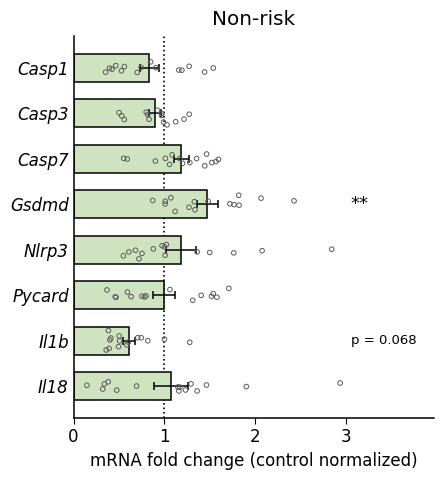

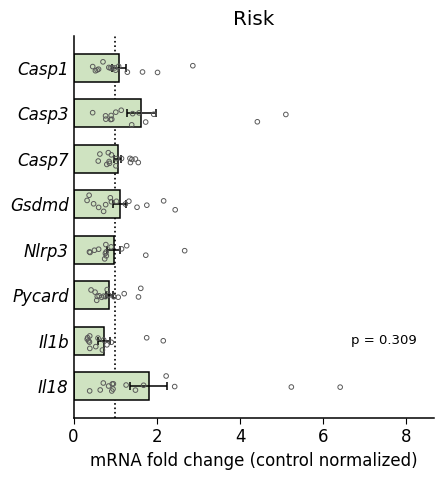

In [ ]:
mpl.rcParams.update({
    'font.family'      : 'sans-serif',
    'font.sans-serif'  : ['Arial', 'DejaVu Sans'],
    'font.size'        : 12,
    'axes.linewidth'   : 1.1,
    'xtick.direction'  : 'out',
    'ytick.direction'  : 'out',
    'xtick.major.size' : 4,
    'ytick.major.size' : 0,
    'savefig.bbox'     : 'tight',
    'pdf.fonttype'     : 42,   # editable text in Illustrator
    'ps.fonttype'      : 42,
})

BAR_FACE   = '#cfe3c1'   # soft green, as in the reference panel
BAR_EDGE   = 'black'
DOT_SIZE   = 11
TOP_FIRST  = True        # first gene of GENES at the top of the panel

def _summary(v):
    if BAR_STAT == 'geometric':
        lv = np.log2(v)
        m  = 2 ** lv.mean()
        se = lv.std(ddof=1) / np.sqrt(len(lv))
        return m, np.array([[m - 2**(lv.mean()-se)], [2**(lv.mean()+se) - m]])
    m = v.mean()
    return m, v.std(ddof=1) / np.sqrt(len(v))

def plot_area(area, ax=None, show_ns=False, xmax=None, star_x=None):
    sub = data[(data.area == area) & (data.group == TX)]
    genes = list(GENES)
    if ax is None:
        fig, ax = plt.subplots(figsize=(4.6, 0.42 * len(genes) + 1.6))
    else:
        fig = ax.figure
    rng = np.random.default_rng(7)

    ypos = {g: (len(genes) - 1 - i if TOP_FIRST else i) for i, g in enumerate(genes)}
    bar_right, data_right = 0.0, 0.0

    for g in genes:
        v = sub[sub.gene == g]['fc'].values
        m, err = _summary(v)
        y = ypos[g]
        ax.barh(y, m, height=0.62, facecolor=BAR_FACE, edgecolor=BAR_EDGE,
                linewidth=1.1, zorder=2)
        ax.errorbar(m, y, xerr=err, color='k', capsize=3, elinewidth=1.1,
                    capthick=1.1, fmt='none', zorder=3)
        ax.scatter(v, rng.normal(y, 0.10, len(v)), s=DOT_SIZE, facecolor='none',
                   edgecolor='0.35', linewidth=0.7, zorder=4)
        bar_right  = max(bar_right, float(np.max(m + np.atleast_1d(err))))
        data_right = max(data_right, v.max())

    # one aligned column for the significance labels, clear of every data point
    star_x = star_x if star_x is not None else data_right * 1.04
    for g in genes:
        p   = res[(res.area == area) & (res.gene == g)][ANNOTATE_WITH].values[0]
        lab = stars(p)
        if g in SHOW_P_GENES:
            txt = 'p < 0.0001' if p < 1e-4 else f'p = {p:.3f}'
            ax.text(star_x, ypos[g], txt, ha='left', va='center', fontsize=9.5)
        elif lab != 'ns' or show_ns:
            ax.text(star_x, ypos[g], lab, ha='left', va='center',
                    fontsize=13 if lab != 'ns' else 10)

    ax.axvline(1.0, ls=':', color='k', lw=1.2, zorder=1)
    ax.set_yticks([ypos[g] for g in genes])
    ax.set_yticklabels(genes, style='italic')
    ax.set_ylim(-0.7, len(genes) - 0.3)
    pad = 1.30 if SHOW_P_GENES else 1.09
    ax.set_xlim(0, xmax if xmax is not None else star_x * pad)
    ax.set_xlabel(f'mRNA fold change (control normalized)')
    ax.set_title(area, pad=8)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    return fig, ax

for area in AREAS:
    fig, _ = plot_area(area)
    tag = area.lower().replace('-', '')
    fig.savefig(f'{SAVE_PREFIX}_{tag}.pdf')
    fig.savefig(f'{SAVE_PREFIX}_{tag}.png', dpi=400)
    plt.show()

### Optional: both areas side by side on a shared x-axis

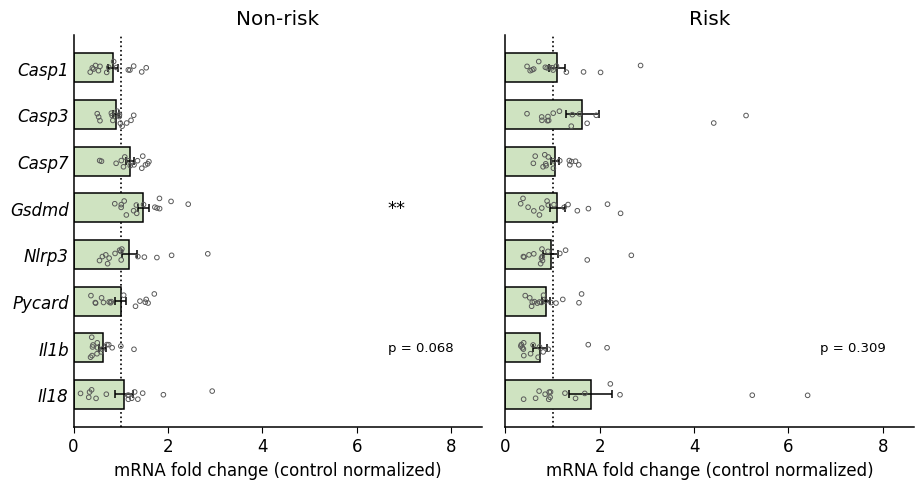

In [ ]:
dmax   = max(data[data.group == TX].groupby('area')['fc'].max())
star_x = dmax * 1.04
fig, axes = plt.subplots(1, 2, figsize=(9.4, 0.42 * len(GENES) + 1.7), sharey=True)
for ax, area in zip(axes, AREAS):
    plot_area(area, ax=ax, xmax=star_x * 1.30, star_x=star_x)
axes[1].set_ylabel('')
fig.tight_layout()
fig.savefig(f'{SAVE_PREFIX}_combined.pdf')
fig.savefig(f'{SAVE_PREFIX}_combined.png', dpi=400)
plt.show()

## 6. Common-calibrator view (Planilha 2 style)

Everything renormalized to **one calibrator: the mean RQ of the non-risk control**. All four groups are now on the same scale, so the panel shows the ischemic response (risk controls rise well above 1) *and* the drug effect on top of it, instead of dividing the injury out.

This is a different question from section 5, not a better answer to the same one — keep the two normalizations in separate figures and never share a dotted line between them. The within-area tests of section 5 remain the primary drug statistics; what this panel adds is the injury axis, tested below **within animal** (each heart contributes its own risk and non-risk sample, so risk-vs-non-risk is paired).

Outlier flags are inherited from section 3: rescaling by a constant shifts log2FC without changing which points Grubbs rejects.

In [ ]:
# --- renormalize every group to the non-risk control ---
common = (long[(long.area == 'Non-risk') & (long.group == CTRL)]
          .groupby('gene')['rq'].mean().rename('calib_common'))

comm = long.merge(common, on='gene')
comm['fc_common']     = comm['rq'] / comm['calib_common']
comm['log2fc_common'] = np.log2(comm['fc_common'])
comm_clean = comm[~comm.outlier] if REMOVE_OUTLIERS else comm

# geometric means per group, for orientation
piv = (comm_clean.groupby(['gene', 'area', 'group'])['log2fc_common']
       .mean().apply(lambda v: 2**v).unstack(['area', 'group']))
piv.round(2)

area   Non-risk              Risk          
group   Control Diacerein Control Diacerein
gene                                       
Casp1      0.89      0.75    4.18      4.57
Casp3      0.92      0.86    2.32      3.40
Casp7      0.98      1.14    2.12      2.27
Gsdmd      0.97      1.41    2.45      2.48
Il18       0.83      0.82    2.33      4.00
Il1b       0.88      0.57    0.37      0.26
Nlrp3      0.94      1.06    1.50      1.38
Pycard     0.95      0.89    3.29      2.92

In [ ]:
# --- paired test of the injury effect: risk vs non-risk within the same animal ---
comm_clean = comm_clean.copy()
comm_clean['animal'] = comm_clean['sample'].str.replace(r'\s*R$', '', regex=True).str.strip()

paired_rows = []
for grp in (CTRL, TX):
    for g in GENES:
        sub = comm_clean[(comm_clean.group == grp) & (comm_clean.gene == g)]
        wide = sub.pivot_table(index='animal', columns='area', values='log2fc_common')
        wide = wide.dropna()
        if len(wide) < 3:
            continue
        diff = wide['Risk'] - wide['Non-risk']
        t = stats.ttest_rel(wide['Risk'], wide['Non-risk'])
        paired_rows.append(dict(group=grp, gene=g, n_pairs=len(wide),
                                ratio_risk_vs_nonrisk=2**diff.mean(),
                                t=t.statistic, p_raw=t.pvalue))
paired = pd.DataFrame(paired_rows)
for grp in (CTRL, TX):
    m = paired.group == grp
    paired.loc[m, 'p_adj'] = bh_fdr(paired.loc[m, 'p_raw'].values)
paired['signif'] = paired['p_adj'].map(stars)
paired.to_csv(f'{SAVE_PREFIX}_paired_risk_vs_nonrisk.csv', index=False)
paired.round(4)

,group,gene,n_pairs,ratio_risk_vs_nonrisk,t,p_raw,p_adj,signif
0,Control,Casp1,15,4.6916,7.2230,0.0000,0.0000,****
1,Control,Casp3,15,2.5313,4.4405,0.0006,0.0007,***
2,Control,Casp7,15,2.1480,7.6472,0.0000,0.0000,****
3,Control,Gsdmd,15,2.5222,6.4517,0.0000,0.0000,****
4,Control,Nlrp3,15,1.6073,3.1149,0.0076,0.0076,**
5,Control,Pycard,15,3.4726,7.7651,0.0000,0.0000,****
6,Control,Il1b,15,0.4248,-6.8662,0.0000,0.0000,****
7,Control,Il18,15,2.7944,3.9768,0.0014,0.0016,**
8,Diacerein,Casp1,15,6.1168,10.0446,0.0000,0.0000,****
9,Diacerein,Casp3,14,4.0513,7.4557,0.0000,0.0000,****


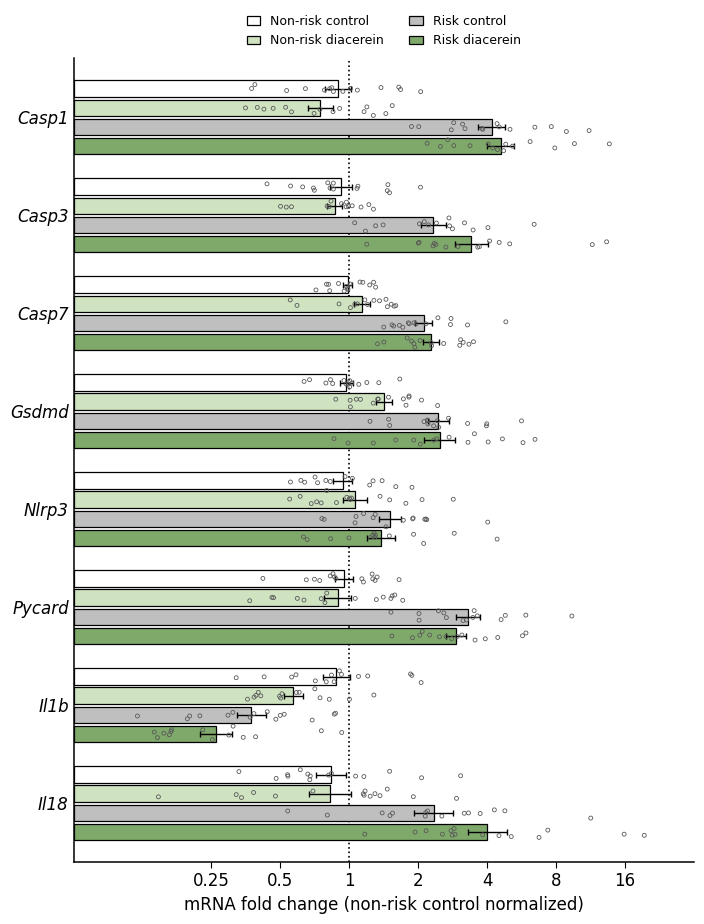

In [ ]:
GROUP_ORDER = [('Non-risk', CTRL), ('Non-risk', TX), ('Risk', CTRL), ('Risk', TX)]
GROUP_LABEL = {('Non-risk', CTRL): 'Non-risk control',
               ('Non-risk', TX  ): 'Non-risk diacerein',
               ('Risk',     CTRL): 'Risk control',
               ('Risk',     TX  ): 'Risk diacerein'}
GROUP_FACE  = {('Non-risk', CTRL): 'white',
               ('Non-risk', TX  ): '#cfe3c1',
               ('Risk',     CTRL): '0.75',
               ('Risk',     TX  ): '#7fa96a'}
LOG_X = True     # log2 x-axis: risk values span an order of magnitude

def plot_common(show_dots=True):
    genes = list(GENES)
    nb_ = len(GROUP_ORDER)
    h   = 0.78 / nb_
    fig, ax = plt.subplots(figsize=(7.2, 0.95 * len(genes) + 1.8))
    rng  = np.random.default_rng(7)
    floor = 2**-4 if LOG_X else 0

    for i, g in enumerate(genes):
        ybase = len(genes) - 1 - i
        for k, key in enumerate(GROUP_ORDER):
            area, grp = key
            v = comm_clean[(comm_clean.gene == g) & (comm_clean.area == area) &
                           (comm_clean.group == grp)]['fc_common'].values
            lv = np.log2(v)
            m  = 2 ** lv.mean()
            se = lv.std(ddof=1) / np.sqrt(len(lv))
            lo, hi = 2**(lv.mean() - se), 2**(lv.mean() + se)
            y  = ybase + 0.39 - (k + 0.5) * h
            ax.barh(y, m - floor, left=floor, height=h * 0.86,
                    facecolor=GROUP_FACE[key], edgecolor='black', linewidth=0.9,
                    zorder=2, label=GROUP_LABEL[key] if i == 0 else None)
            ax.errorbar(m, y, xerr=[[m - lo], [hi - m]], color='k', capsize=2.5,
                        elinewidth=1.0, capthick=1.0, fmt='none', zorder=3)
            if show_dots:
                ax.scatter(v, rng.normal(y, h * 0.16, len(v)), s=8,
                           facecolor='none', edgecolor='0.35', linewidth=0.6, zorder=4)

    ax.axvline(1.0, ls=':', color='k', lw=1.2, zorder=1)
    if LOG_X:
        ax.set_xscale('log', base=2)
        ticks = [0.25, 0.5, 1, 2, 4, 8, 16]
        ax.set_xticks(ticks)
        ax.set_xticklabels([str(t) for t in ticks])
        ax.set_xlim(floor, max(32, comm_clean['fc_common'].max() * 1.2))
    ax.set_yticks(range(len(genes)))
    ax.set_yticklabels(genes[::-1], style='italic')
    ax.set_ylim(-0.6, len(genes) - 0.4)
    ax.set_xlabel('mRNA fold change (non-risk control normalized)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, fontsize=9, ncol=2, loc='lower center',
              bbox_to_anchor=(0.5, 1.0), handlelength=1.1)
    fig.tight_layout()
    return fig, ax

fig, _ = plot_common()
fig.savefig(f'{SAVE_PREFIX}_common_calibrator.pdf')
fig.savefig(f'{SAVE_PREFIX}_common_calibrator.png', dpi=400)
plt.show()

## 7. Two-way mixed ANOVA — treatment × ischemic injury

Design per gene: **Treatment** (control vs diacerein) is *between* animals; **Area** (non-risk vs risk) is *within* animal, since each heart gives both samples. This is a 2 × 2 split-plot design, i.e. a two-way ANOVA with repeated measures on Area (what GraphPad calls "two-way RM ANOVA, matched on one factor").

Response: log2 RQ on the common calibrator (the calibrator is a constant per gene, so it changes no F or p).

Three effects per gene:
- **Area (ischemia)** — does the risk zone differ from remote myocardium, averaged over treatment?
- **Treatment (diacerein)** — does diacerein shift expression, averaged over both areas?
- **Treatment × Area** — does diacerein change the *size of the ischemic response*? This is the term that answers "is the drug effect different in injured tissue."

With a 2-level within factor the ANOVA is exact and simple: the Area effect and the interaction are tests on each animal's within-heart difference (risk − non-risk), and the Treatment effect is a test on each animal's mean of the two areas. Unequal group sizes are handled with unweighted (Type III) marginal means. Only animals with both areas present for that gene enter (complete pairs); T9 is absent in both areas, and a Grubbs-rejected value removes that animal from that gene only.

Post hoc: Šidák-corrected (4 comparisons per gene) — diacerein vs control within each area (unpaired Welch) and risk vs non-risk within each arm (paired). BH-FDR across the 8 genes is applied separately to each ANOVA effect.

In [ ]:
def mixed_anova_2x2(wide_c, wide_t):
    """wide_*: DataFrame indexed by animal with columns 'Non-risk', 'Risk' (log2 values).
    Returns dict of F, df and p for Treatment, Area and Treatment x Area (Type III)."""
    dc = (wide_c['Risk'] - wide_c['Non-risk']).values
    dt = (wide_t['Risk'] - wide_t['Non-risk']).values
    mc = wide_c.mean(axis=1).values
    mt = wide_t.mean(axis=1).values
    n1, n2 = len(dc), len(dt)
    df_err = n1 + n2 - 2
    out = {}

    # within-subject error: pooled variance of the difference scores
    sp_d = np.sqrt(((n1-1)*dc.var(ddof=1) + (n2-1)*dt.var(ddof=1)) / df_err)
    # Area main effect: unweighted mean of the two group mean differences vs 0
    t_area = ((dc.mean() + dt.mean()) / 2) / (sp_d * np.sqrt((1/n1 + 1/n2) / 4))
    # Interaction: do the two groups differ in their ischemic difference?
    t_int  = (dt.mean() - dc.mean()) / (sp_d * np.sqrt(1/n1 + 1/n2))
    # between-subject error: pooled variance of subject means
    sp_m = np.sqrt(((n1-1)*mc.var(ddof=1) + (n2-1)*mt.var(ddof=1)) / df_err)
    t_tx   = (mt.mean() - mc.mean()) / (sp_m * np.sqrt(1/n1 + 1/n2))

    for name, t in (('Treatment', t_tx), ('Area', t_area), ('Treatment x Area', t_int)):
        F = t**2
        out[name] = dict(F=F, df1=1, df2=df_err,
                         p=stats.f.sf(F, 1, df_err),
                         partial_eta2=F / (F + df_err))
    return out, n1, n2

sidak = lambda p, k=4: 1 - (1 - p)**k

anova_rows, posthoc_rows = [], []
for g in GENES:
    sub = comm_clean[comm_clean.gene == g]
    wide = {}
    for grp in (CTRL, TX):
        w = (sub[sub.group == grp]
             .pivot_table(index='animal', columns='area', values='log2fc_common')
             .dropna())
        wide[grp] = w
    res_g, n1, n2 = mixed_anova_2x2(wide[CTRL], wide[TX])
    for eff, r in res_g.items():
        anova_rows.append(dict(gene=g, effect=eff, n_ctrl=n1, n_tx=n2, **r))

    # post hoc
    for area in AREAS:
        a, b = wide[TX][area].values, wide[CTRL][area].values
        tt = stats.ttest_ind(a, b, equal_var=False)
        posthoc_rows.append(dict(gene=g, comparison=f'{TX} vs {CTRL} | {area}',
                                 ratio=2**(a.mean() - b.mean()),
                                 p_raw=tt.pvalue, p_sidak=sidak(tt.pvalue)))
    for grp in (CTRL, TX):
        w = wide[grp]
        tt = stats.ttest_rel(w['Risk'], w['Non-risk'])
        posthoc_rows.append(dict(gene=g, comparison=f'Risk vs Non-risk | {grp}',
                                 ratio=2**(w['Risk'] - w['Non-risk']).mean(),
                                 p_raw=tt.pvalue, p_sidak=sidak(tt.pvalue)))

anova = pd.DataFrame(anova_rows)
for eff in anova.effect.unique():
    m = anova.effect == eff
    anova.loc[m, 'p_adj'] = bh_fdr(anova.loc[m, 'p'].values)
anova['signif'] = anova['p_adj'].map(stars)
posthoc = pd.DataFrame(posthoc_rows)
posthoc['signif'] = posthoc['p_sidak'].map(stars)

anova.to_csv(f'{SAVE_PREFIX}_anova_2way.csv', index=False)
posthoc.to_csv(f'{SAVE_PREFIX}_anova_posthoc.csv', index=False)

(anova.pivot(index='gene', columns='effect', values='p_adj')
      .loc[GENES, ['Area', 'Treatment', 'Treatment x Area']]
      .round(4))

effect,Area,Treatment,Treatment x Area
gene,,,
Casp1,0.0000,0.8244,0.6735
Casp3,0.0000,0.2963,0.3816
Casp7,0.0000,0.2963,0.7868
Gsdmd,0.0000,0.2963,0.3816
Nlrp3,0.0005,0.9583,0.6735
Pycard,0.0000,0.6191,0.7868
Il1b,0.0000,0.2755,0.7868
Il18,0.0000,0.2963,0.3816


In [ ]:
L = []
L.append('TWO-WAY MIXED ANOVA: Treatment (between) x Area (within animal)')
L.append('=' * 78)
L.append('Response: log2 RQ (Gapdh-normalized), common calibrator = non-risk control.')
L.append('Type III (unweighted means); complete pairs only; Grubbs outliers excluded.')
L.append('BH-FDR across 8 genes per effect. Post hoc: Sidak, 4 comparisons per gene.')
L.append('')
for g in GENES:
    a = anova[anova.gene == g].set_index('effect')
    n1, n2 = int(a['n_ctrl'].iloc[0]), int(a['n_tx'].iloc[0])
    L.append(f'{g}  (complete pairs: {n1} control, {n2} diacerein)')
    for eff in ('Area', 'Treatment', 'Treatment x Area'):
        r = a.loc[eff]
        L.append(f'   {eff:17s} F(1,{int(r.df2)}) = {r.F:7.2f}, {fmt_p(r.p):12s} '
                 f'BH {fmt_p(r.p_adj):12s} partial eta2 = {r.partial_eta2:.2f}  {r.signif}')
    for _, r in posthoc[posthoc.gene == g].iterrows():
        L.append(f'     post hoc  {r.comparison:34s} ratio {r.ratio:5.2f}  '
                 f'Sidak {fmt_p(r.p_sidak)}  {r.signif}')
    L.append('')
anova_report = '\n'.join(L)
print(anova_report)
with open(f'{SAVE_PREFIX}_anova_report.txt', 'w') as f:
    f.write(anova_report)

TWO-WAY MIXED ANOVA: Treatment (between) x Area (within animal)
Response: log2 RQ (Gapdh-normalized), common calibrator = non-risk control.
Type III (unweighted means); complete pairs only; Grubbs outliers excluded.
BH-FDR across 8 genes per effect. Post hoc: Sidak, 4 comparisons per gene.

Casp1  (complete pairs: 15 control, 15 diacerein)
   Area              F(1,28) =  143.90, p < 0.0001   BH p < 0.0001   partial eta2 = 0.84  ****
   Treatment         F(1,28) =    0.13, p = 0.7213   BH p = 0.8244   partial eta2 = 0.00  ns
   Treatment x Area  F(1,28) =    0.90, p = 0.3513   BH p = 0.6735   partial eta2 = 0.03  ns
     post hoc  Diacerein vs Control | Non-risk    ratio  0.84  Sidak p = 0.8121  ns
     post hoc  Diacerein vs Control | Risk        ratio  1.09  Sidak p = 0.9835  ns
     post hoc  Risk vs Non-risk | Control         ratio  4.69  Sidak p < 0.0001  ****
     post hoc  Risk vs Non-risk | Diacerein       ratio  6.12  Sidak p < 0.0001  ****

Casp3  (complete pairs: 15 control, 

### Common-calibrator figure with the ANOVA effects

Same panel as section 6, with a three-column key on the right: **I** = ischemia (Area), **D** = diacerein (Treatment), **I×D** = interaction. Symbols are BH-adjusted ANOVA p values.

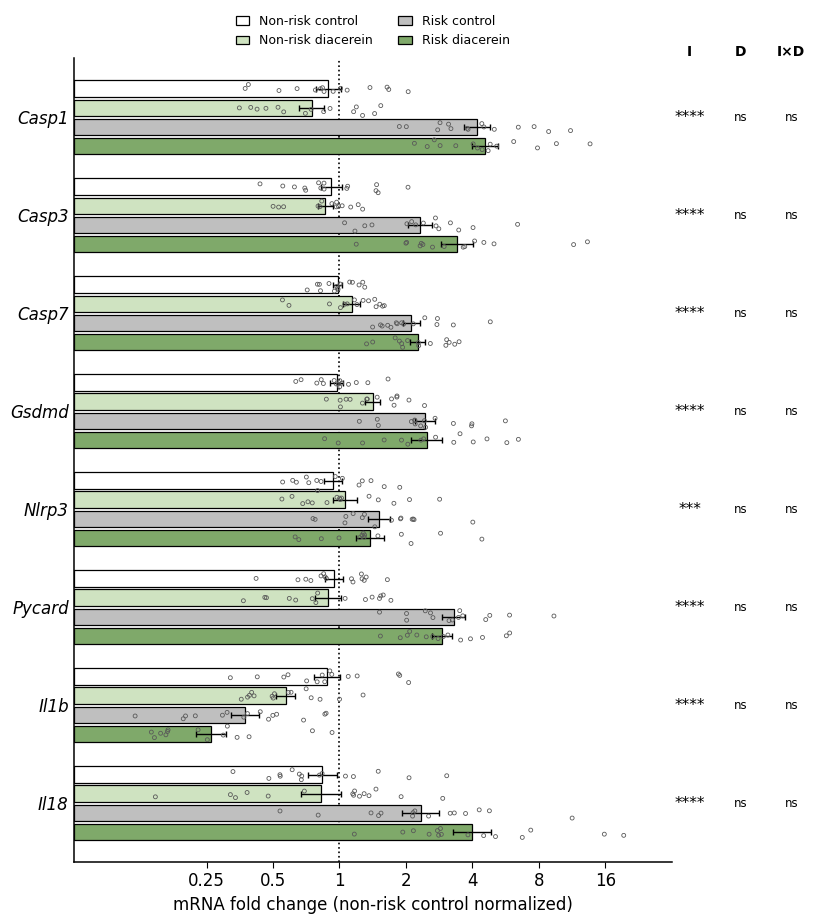

In [ ]:
def plot_common_anova():
    fig, ax = plot_common()
    fig.set_size_inches(8.6, fig.get_size_inches()[1])
    genes = list(GENES)
    cols  = [('Area', 'I'), ('Treatment', 'D'), ('Treatment x Area', 'I×D')]
    x0 = 1.03
    for j, (eff, lab) in enumerate(cols):
        x = x0 + j * 0.085
        ax.text(x, 1.0, lab, transform=ax.transAxes, ha='center', va='bottom',
                fontsize=10, fontweight='bold')
        for i, g in enumerate(genes):
            p = anova[(anova.gene == g) & (anova.effect == eff)]['p_adj'].values[0]
            ybase = len(genes) - 1 - i
            ax.text(x, ybase, stars(p), transform=ax.get_yaxis_transform(),
                    ha='center', va='center', fontsize=11 if stars(p) != 'ns' else 8.5)
    fig.tight_layout()
    return fig, ax

fig, _ = plot_common_anova()
fig.savefig(f'{SAVE_PREFIX}_common_calibrator_anova.pdf')
fig.savefig(f'{SAVE_PREFIX}_common_calibrator_anova.png', dpi=400)
plt.show()

## 8. Compact panels annotated with the two-way ANOVA

Same compact layout as section 5 (diacerein only, each area normalized to its own control), but the statistics come from the two-way mixed ANOVA of section 7.

This is legitimate because **the calibrator never enters the ANOVA**: dividing by any constant shifts all log2 values of a gene equally, so every F, p and post hoc is identical whichever control is used for display. The ANOVA was run on the common-calibrator scale; the bars are simply redrawn relative to each area's control.

- Asterisks = Šidák-corrected post hoc, diacerein vs control **within that area** (4 comparisons per gene).
- The dots are restricted to the animals the ANOVA used (complete risk/non-risk pairs), so figure and statistics describe the same data.
- ANOVA main effects and interaction go in the figure legend; the cell after the plots writes ready-to-paste legend text.

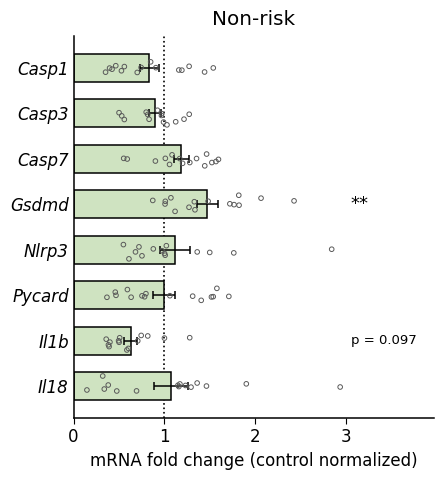

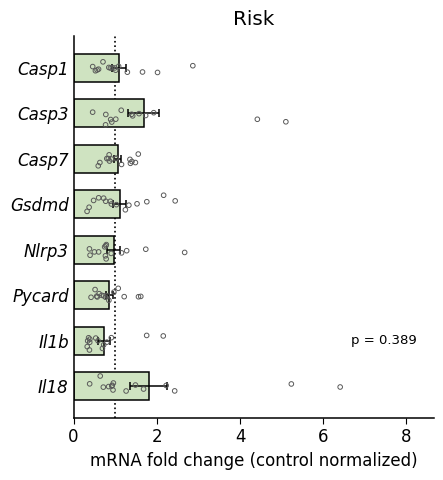

In [ ]:
# animals with both areas for each gene & group (the ANOVA sample)
pairs = (comm_clean.groupby(['gene', 'group', 'animal'])['area'].nunique()
         .reset_index().query('area == 2')[['gene', 'group', 'animal']])
anova_data = comm_clean.merge(pairs, on=['gene', 'group', 'animal'])

def posthoc_p(gene, area):
    r = posthoc[(posthoc.gene == gene) &
                (posthoc.comparison == f'{TX} vs {CTRL} | {area}')]
    return r['p_sidak'].values[0]

def plot_area_anova(area, ax=None, xmax=None, star_x=None, show_ns=False):
    sub = anova_data[(anova_data.area == area) & (anova_data.group == TX)]
    genes = list(GENES)
    if ax is None:
        fig, ax = plt.subplots(figsize=(4.6, 0.42 * len(genes) + 1.6))
    else:
        fig = ax.figure
    rng = np.random.default_rng(7)
    ypos = {g: len(genes) - 1 - i for i, g in enumerate(genes)}
    data_right = 0.0

    for g in genes:
        v = sub[sub.gene == g]['fc'].values          # within-area FC (display only)
        m, err = _summary(v)
        y = ypos[g]
        ax.barh(y, m, height=0.62, facecolor=BAR_FACE, edgecolor=BAR_EDGE,
                linewidth=1.1, zorder=2)
        ax.errorbar(m, y, xerr=err, color='k', capsize=3, elinewidth=1.1,
                    capthick=1.1, fmt='none', zorder=3)
        ax.scatter(v, rng.normal(y, 0.10, len(v)), s=DOT_SIZE, facecolor='none',
                   edgecolor='0.35', linewidth=0.7, zorder=4)
        data_right = max(data_right, v.max())

    star_x = star_x if star_x is not None else data_right * 1.04
    for g in genes:
        p   = posthoc_p(g, area)
        lab = stars(p)
        if g in SHOW_P_GENES:
            txt = 'p < 0.0001' if p < 1e-4 else f'p = {p:.3f}'
            ax.text(star_x, ypos[g], txt, ha='left', va='center', fontsize=9.5)
        elif lab != 'ns' or show_ns:
            ax.text(star_x, ypos[g], lab, ha='left', va='center',
                    fontsize=13 if lab != 'ns' else 10)

    ax.axvline(1.0, ls=':', color='k', lw=1.2, zorder=1)
    ax.set_yticks([ypos[g] for g in genes])
    ax.set_yticklabels(genes, style='italic')
    ax.set_ylim(-0.7, len(genes) - 0.3)
    pad = 1.30 if SHOW_P_GENES else 1.09
    ax.set_xlim(0, xmax if xmax is not None else star_x * pad)
    ax.set_xlabel('mRNA fold change (control normalized)')
    ax.set_title(area, pad=8)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    return fig, ax

for area in AREAS:
    fig, _ = plot_area_anova(area)
    tag = area.lower().replace('-', '')
    fig.savefig(f'{SAVE_PREFIX}_{tag}_anova.pdf')
    fig.savefig(f'{SAVE_PREFIX}_{tag}_anova.png', dpi=400)
    plt.show()

In [ ]:
# --- ready-to-paste legend text with the ANOVA effects ---
def eff_str(g, eff):
    r = anova[(anova.gene == g) & (anova.effect == eff)].iloc[0]
    return f'F(1,{int(r.df2)}) = {r.F:.2f}, p{"<0.0001" if r.p_adj < 1e-4 else f"={r.p_adj:.3f}"}'

legend = ['Two-way repeated-measures ANOVA (treatment x area, area matched within animal) '
          'on log2-transformed expression; BH-adjusted across genes. Asterisks: '
          'Sidak-corrected post hoc, diacerein vs control within each area.']
for g in GENES:
    legend.append(f'{g}: ischemia {eff_str(g, "Area")}; diacerein {eff_str(g, "Treatment")}; '
                  f'interaction {eff_str(g, "Treatment x Area")}.')
legend_text = ' '.join(legend)
print(legend_text)
with open(f'{SAVE_PREFIX}_anova_legend.txt', 'w') as f:
    f.write(legend_text)

Two-way repeated-measures ANOVA (treatment x area, area matched within animal) on log2-transformed expression; BH-adjusted across genes. Asterisks: Sidak-corrected post hoc, diacerein vs control within each area. Casp1: ischemia F(1,28) = 143.90, p<0.0001; diacerein F(1,28) = 0.13, p=0.824; interaction F(1,28) = 0.90, p=0.674. Casp3: ischemia F(1,27) = 67.93, p<0.0001; diacerein F(1,27) = 2.36, p=0.296; interaction F(1,27) = 2.77, p=0.382. Casp7: ischemia F(1,28) = 97.68, p<0.0001; diacerein F(1,28) = 1.85, p=0.296; interaction F(1,28) = 0.24, p=0.787. Gsdmd: ischemia F(1,28) = 61.20, p<0.0001; diacerein F(1,28) = 2.73, p=0.296; interaction F(1,28) = 3.65, p=0.382. Nlrp3: ischemia F(1,27) = 15.47, p=0.001; diacerein F(1,27) = 0.00, p=0.958; interaction F(1,27) = 0.67, p=0.674. Pycard: ischemia F(1,28) = 141.73, p<0.0001; diacerein F(1,28) = 0.55, p=0.619; interaction F(1,28) = 0.07, p=0.787. Il1b: ischemia F(1,27) = 73.38, p<0.0001; diacerein F(1,27) = 4.96, p=0.275; interaction F(1,27

## 9. Figure 1A — risk area only, submission format

Risk-area **control** and **diacerein** on the non-risk-control scale, so the ischemic induction (bars above the dotted line) and the drug effect (control vs diacerein) are both visible in one compact panel.

Symbols (both from the section-7 ANOVA post hoc, Šidák-corrected):
- **#** on the control bar = ischemia: risk control vs non-risk control (the dotted line), paired within animal.
- **\*** (or the numeric p for genes in `SHOW_P_GENES`) on the diacerein bar = diacerein vs control within the risk area.

Sizing follows the American Heart Association journal figure guidelines: type inside the figure is 8 pt (AHA asks for 8–10 pt), there is no heading drawn on the panel — the heading information belongs in the figure legend — and the panel letter is an uppercase letter at the upper left. The panel is drawn at its **physical print size**, one third of an 18 cm figure, so nothing needs rescaling when it is placed into the assembled Figure 1. Liberation Sans is used as the Arial stand-in (identical metrics); text is exported as editable TrueType, so swapping to Arial in Illustrator is one click. Raster copies are written at 600 dpi.

In [ ]:
# --- Arial-metric font for Colab (Liberation Sans is metric-identical to Arial) ---
import subprocess, matplotlib.font_manager as fm
if IN_COLAB and not any('Liberation Sans' in f.name for f in fm.fontManager.ttflist):
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-liberation'], check=False)
    for p in fm.findSystemFonts():
        if 'Liberation' in p:
            fm.fontManager.addfont(p)

CM = 1 / 2.54
# Figure style for the submitted panels. AHA journals ask for 8-10 pt type inside the
# figure and no heading drawn on the panel; headings go in the legend.
AHA = {
    'font.family'      : 'sans-serif',
    'font.sans-serif'  : ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans'],
    'font.size'        : 8,
    'axes.labelsize'   : 8,
    'xtick.labelsize'  : 8,
    'ytick.labelsize'  : 8,
    'legend.fontsize'  : 8,
    'axes.linewidth'   : 0.6,
    'xtick.major.width': 0.6,
    'ytick.major.width': 0.6,
    'xtick.major.size' : 2.5,
    'ytick.major.size' : 0,
    'xtick.direction'  : 'out',
    'pdf.fonttype'     : 42,
    'ps.fonttype'      : 42,
    'savefig.dpi'      : 600,
    'savefig.bbox'     : 'standard',   # keep the exact physical size (no tight cropping)
    'mathtext.fontset' : 'custom',
    'mathtext.it'      : 'Liberation Sans:italic',
    'mathtext.rm'      : 'Liberation Sans',
}

Panel size: 6.0 x 7.2 cm (one third of the 18 cm assembled Figure 1)


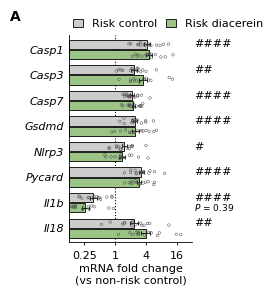

In [ ]:
PANEL_W_CM, PANEL_H_CM = 6.0, 7.2    # one-third of an 18 cm figure
PANEL_LABEL = 'A'                     # set to None if you letter panels in Illustrator
RISK_FACE   = {CTRL: '0.80', TX: '#9cc487'}
LOG_X_1A    = True

def ischemia_p(gene):
    r = posthoc[(posthoc.gene == gene) &
                (posthoc.comparison == f'Risk vs Non-risk | {CTRL}')]
    return r['p_sidak'].values[0]

def hashes(p):
    return {'****': '####', '***': '###', '**': '##', '*': '#'}.get(stars(p), '')

def fig1a():
    with mpl.rc_context(AHA):
        fig = plt.figure(figsize=(PANEL_W_CM * CM, PANEL_H_CM * CM))
        ax  = fig.add_axes([0.26, 0.17, 0.52, 0.73])   # fixed margins -> exact print size
        genes = list(GENES)
        h     = 0.36
        rng   = np.random.default_rng(7)
        floor = 2**-3 if LOG_X_1A else 0
        risk  = anova_data[anova_data.area == 'Risk']
        xtext = 1.02                                   # symbol column, axes coords

        for i, g in enumerate(genes):
            ybase = len(genes) - 1 - i
            for grp, dy in ((CTRL, +h/2 + 0.02), (TX, -h/2 - 0.02)):
                v  = risk[(risk.gene == g) & (risk.group == grp)]['fc_common'].values
                lv = np.log2(v)
                m  = 2 ** lv.mean()
                se = lv.std(ddof=1) / np.sqrt(len(lv))
                y  = ybase + dy
                ax.barh(y, m - floor, left=floor, height=h, facecolor=RISK_FACE[grp],
                        edgecolor='black', linewidth=0.6, zorder=2,
                        label=('Risk control' if grp == CTRL else 'Risk diacerein') if i == 0 else None)
                ax.errorbar(m, y, xerr=[[m - 2**(lv.mean()-se)], [2**(lv.mean()+se) - m]],
                            color='k', capsize=1.5, elinewidth=0.6, capthick=0.6,
                            fmt='none', zorder=3)
                ax.scatter(v, rng.normal(y, h * 0.14, len(v)), s=3.5, facecolor='none',
                           edgecolor='0.3', linewidth=0.35, zorder=4)

            # symbols: ischemia on the control row, drug on the diacerein row
            ax.text(xtext, ybase + h/2 + 0.02, hashes(ischemia_p(g)),
                    transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=8)
            p = posthoc_p(g, 'Risk')
            if g in SHOW_P_GENES:
                lab = '$P$ < 0.0001' if p < 1e-4 else f'$P$ = {p:.2f}'
                fs  = 6.5
            else:
                lab = stars(p) if stars(p) != 'ns' else ''
                fs  = 8
            ax.text(xtext, ybase - h/2 - 0.02, lab, transform=ax.get_yaxis_transform(),
                    ha='left', va='center', fontsize=fs)

        ax.axvline(1.0, ls=':', color='k', lw=0.8, zorder=1)
        if LOG_X_1A:
            ax.set_xscale('log', base=2)
            ticks = [0.25, 1, 4, 16]
            ax.set_xticks(ticks)
            ax.set_xticklabels(['0.25', '1', '4', '16'])
            ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
            ax.set_xlim(floor, 32)
        ax.set_yticks(range(len(genes)))
        ax.set_yticklabels(genes[::-1], style='italic')
        ax.set_ylim(-0.55, len(genes) - 0.45)
        ax.set_xlabel('mRNA fold change\n(vs non-risk control)', labelpad=2)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(-0.02, 1.0),
                  ncol=2, handlelength=0.9, handleheight=0.7, columnspacing=0.8,
                  borderaxespad=0.2)
        if PANEL_LABEL:
            fig.text(0.01, 0.99, PANEL_LABEL, ha='left', va='top',
                     fontsize=10, fontweight='bold')
    return fig

fig = fig1a()
with mpl.rc_context(AHA):          # fonts are resolved at save time, so save inside the style
    fig.savefig(f'{SAVE_PREFIX}_Fig1A.pdf')
    fig.savefig(f'{SAVE_PREFIX}_Fig1A.tiff', dpi=600,
                pil_kwargs={'compression': 'tiff_lzw'})
    fig.savefig(f'{SAVE_PREFIX}_Fig1A.png', dpi=600)
w, h_ = fig.get_size_inches()
print(f'Panel size: {w/CM:.1f} x {h_/CM:.1f} cm (one third of the 18 cm assembled Figure 1)')
plt.show()

In [ ]:
def n_range(grp):
    n = (anova_data[(anova_data.area == 'Risk') & (anova_data.group == grp)]
         .groupby('gene')['animal'].nunique())
    return f'{n.min()}' if n.min() == n.max() else f'{n.min()}-{n.max()}'

legend_1a = (
    '(A) Pyroptosis-pathway mRNA in the ischemic (risk) area of control and diacerein-treated '
    'animals, expressed relative to the non-risk area of controls (dotted line; 2^-ddCt, Gapdh '
    'reference). Bars, geometric mean +/- SEM; circles, individual animals '
    f'(n = {n_range(CTRL)} control, {n_range(TX)} diacerein per gene; '
    'outliers removed by Grubbs test). Two-way repeated-measures ANOVA (treatment x area) on log2 '
    'expression with Sidak post hoc tests: # risk vs non-risk control (ischemia); '
    '* diacerein vs control within the risk area. #P < 0.05, ##P < 0.01, ###P < 0.001, ####P < 0.0001.')
print(legend_1a)
with open(f'{SAVE_PREFIX}_Fig1A_legend.txt', 'w') as f:
    f.write(legend_1a)

(A) Pyroptosis-pathway mRNA in the ischemic (risk) area of control and diacerein-treated animals, expressed relative to the non-risk area of controls (dotted line; 2^-ddCt, Gapdh reference). Bars, geometric mean +/- SEM; circles, individual animals (n = 15 control, 14-15 diacerein per gene; outliers removed by Grubbs test). Two-way repeated-measures ANOVA (treatment x area) on log2 expression with Sidak post hoc tests: # risk vs non-risk control (ischemia); * diacerein vs control within the risk area. #P < 0.05, ##P < 0.01, ###P < 0.001, ####P < 0.0001.


## 10. Ischemic response under diacerein — per-animal risk / non-risk ratio (submission format)

One bar per gene: for each diacerein-treated heart, risk-area expression divided by **that same heart's** non-risk area. The dotted line at 1 means no ischemic change. Bars are the geometric mean ± SEM of the per-animal ratios; circles are individual hearts.

Because each animal is its own reference, this is exactly the paired contrast *Risk vs Non-risk | Diacerein* from the section-7 post hoc (Šidák-corrected), shown as #.

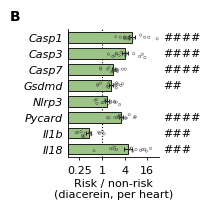

(B) Ischemic response in diacerein-treated hearts: risk-area expression divided by the non-risk area of the same heart (dotted line, no change). Bars, geometric mean +/- SEM of per-animal ratios; circles, individual hearts (n = 14-15 per gene). Paired Sidak post hoc from the two-way repeated-measures ANOVA: #P < 0.05, ##P < 0.01, ###P < 0.001, ####P < 0.0001.


In [ ]:
PANEL2_W_CM, PANEL2_H_CM = 4.6, 5.0
BAR_H_1B = 0.65                          # bar thickness (1 = bars touching)
PANEL2_LABEL = 'B'                       # None if you letter panels in Illustrator

def ischemia_p_tx(gene):
    r = posthoc[(posthoc.gene == gene) &
                (posthoc.comparison == f'Risk vs Non-risk | {TX}')]
    return r['p_sidak'].values[0]

def per_animal_ratio(gene, grp=TX):
    w = (anova_data[(anova_data.gene == gene) & (anova_data.group == grp)]
         .pivot_table(index='animal', columns='area', values='log2fc_common').dropna())
    return w['Risk'] - w['Non-risk']          # log2 ratio per heart

def fig_ratio_tx():
    with mpl.rc_context(AHA):
        fig = plt.figure(figsize=(PANEL2_W_CM * CM, PANEL2_H_CM * CM))
        # margins in cm, so resizing the panel keeps text spacing constant
        L, R, B, T = 1.52, 0.78, 1.20, 0.55
        ax  = fig.add_axes([L / PANEL2_W_CM, B / PANEL2_H_CM,
                            1 - (L + R) / PANEL2_W_CM, 1 - (B + T) / PANEL2_H_CM])
        genes = list(GENES)
        rng   = np.random.default_rng(7)
        floor = 2**-3
        for i, g in enumerate(genes):
            y  = len(genes) - 1 - i
            lr = per_animal_ratio(g).values
            m  = 2 ** lr.mean()
            se = lr.std(ddof=1) / np.sqrt(len(lr))
            ax.barh(y, m - floor, left=floor, height=BAR_H_1B, facecolor=RISK_FACE[TX],
                    edgecolor='black', linewidth=0.6, zorder=2)
            ax.errorbar(m, y, xerr=[[m - 2**(lr.mean()-se)], [2**(lr.mean()+se) - m]],
                        color='k', capsize=1.5, elinewidth=0.6, capthick=0.6,
                        fmt='none', zorder=3)
            ax.scatter(2**lr, rng.normal(y, BAR_H_1B * 0.16, len(lr)), s=2.8, facecolor='none',
                       edgecolor='0.3', linewidth=0.35, zorder=4)
            ax.text(1.05, y, hashes(ischemia_p_tx(g)), transform=ax.get_yaxis_transform(),
                    ha='left', va='center', fontsize=8)

        ax.axvline(1.0, ls=':', color='k', lw=0.8, zorder=1)
        ax.set_xscale('log', base=2)
        ax.set_xticks([0.25, 1, 4, 16])
        ax.set_xticklabels(['0.25', '1', '4', '16'])
        ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
        ax.set_xlim(floor, 32)
        ax.set_yticks(range(len(genes)))
        ax.set_yticklabels(genes[::-1], style='italic')
        ax.set_ylim(-0.5, len(genes) - 0.5)
        ax.set_xlabel('Risk / non-risk\n(diacerein, per heart)', labelpad=2)
        ax.spines[['top', 'right']].set_visible(False)
        if PANEL2_LABEL:
            fig.text(0.01, 0.99, PANEL2_LABEL, ha='left', va='top',
                     fontsize=10, fontweight='bold')
    return fig

fig = fig_ratio_tx()
with mpl.rc_context(AHA):
    fig.savefig(f'{SAVE_PREFIX}_Fig1B_ratio_diacerein.pdf')
    fig.savefig(f'{SAVE_PREFIX}_Fig1B_ratio_diacerein.tiff', dpi=600,
                pil_kwargs={'compression': 'tiff_lzw'})
    fig.savefig(f'{SAVE_PREFIX}_Fig1B_ratio_diacerein.png', dpi=600)
plt.show()

n_tx = [len(per_animal_ratio(g)) for g in GENES]
legend_1b = ('(B) Ischemic response in diacerein-treated hearts: risk-area expression divided by the '
             'non-risk area of the same heart (dotted line, no change). Bars, geometric mean +/- SEM of '
             f'per-animal ratios; circles, individual hearts (n = {min(n_tx)}-{max(n_tx)} per gene). '
             'Paired Sidak post hoc from the two-way repeated-measures ANOVA: '
             '#P < 0.05, ##P < 0.01, ###P < 0.001, ####P < 0.0001.')
print(legend_1b)
with open(f'{SAVE_PREFIX}_Fig1B_legend.txt', 'w') as f:
    f.write(legend_1b)

### Download everything (Colab)

In [ ]:
# bundle every output into one zip (avoids 30+ separate browser download prompts)
import shutil, glob, os
ZIP_DIR = 'all_outputs'                     # must NOT start with SAVE_PREFIX
shutil.rmtree(ZIP_DIR, ignore_errors=True)
os.makedirs(ZIP_DIR)
for f in glob.glob(f'{SAVE_PREFIX}_*'):
    if os.path.isfile(f):
        shutil.copy(f, ZIP_DIR)
shutil.make_archive(ZIP_DIR, 'zip', ZIP_DIR)
print(f"{len(os.listdir(ZIP_DIR))} files zipped into {ZIP_DIR}.zip")
if IN_COLAB:
    from google.colab import files
    files.download(f'{ZIP_DIR}.zip')

31 files zipped into all_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>